Maior float32: 3.4028235e+38
Maior float64: 1.7976931348623157e+308
dt=0.001, float32: 2000 passos sem overflow.
dt=0.002, float32: falha no passo 121, t=0.2420 s - overflow encountered in subtract
dt=0.001, float64: 2000 passos sem overflow.
dt=0.002, float64: falha no passo 917, t=1.8340 s - overflow encountered in add


/usr/local/lib/python3.13/dist-packages/matplotlib/scale.py:253: RuntimeWarning: overflow encountered in power
  return np.power(self.base, values)


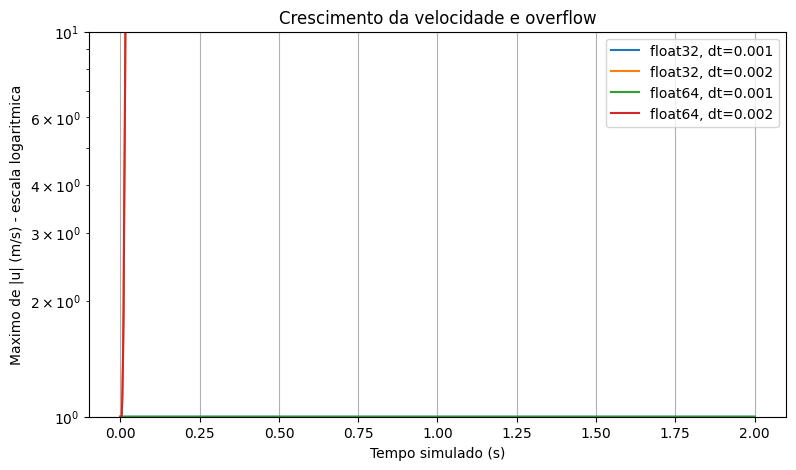

In [3]:
import numpy as np
import matplotlib.pyplot as plt


def simular(dt, tipo=np.float32, passos=2000, pontos=21):
    """Simula difusao de velocidade e detecta falhas."""

    H = 0.01
    nu = 1e-4

    y = np.linspace(0, H, pontos)
    dy = H / (pontos - 1)

    # Coeficientes no tipo numerico escolhido.
    r = tipo(nu * dt / dy**2)
    dois = tipo(2)

    # Fluido parado e placa em y=0 em movimento.
    u = np.zeros(pontos, dtype=tipo)
    u[0] = tipo(1)

    tempos = [0.0]
    maximos = [float(np.max(np.abs(u)))]
    falha = None

    # Transforma avisos numericos em excecoes.
    with np.errstate(over="raise", invalid="raise"):
        for passo in range(1, passos + 1):
            try:
                novo = u.copy()

                # Atualiza o interior e preserva as paredes.
                novo[1:-1] = (
                    u[1:-1]
                    + r * (
                        u[2:] - dois * u[1:-1] + u[:-2]
                    )
                )

            except FloatingPointError as erro:
                falha = passo
                print(
                    f"dt={dt}, {tipo.__name__}: "
                    f"falha no passo {passo}, "
                    f"t={passo * dt:.4f} s - {erro}"
                )
                break

            u = novo
            tempos.append(passo * dt)
            maximos.append(float(np.max(np.abs(u))))

    if falha is None:
        print(
            f"dt={dt}, {tipo.__name__}: "
            f"{passos} passos sem overflow."
        )

    return {
        "y": y,
        "u": u,
        "tempos": tempos,
        "maximos": maximos,
        "r": float(r),
        "falha": falha,
    }


print("Maior float32:", np.finfo(np.float32).max)
print("Maior float64:", np.finfo(np.float64).max)

resultados = {}

for tipo in (np.float32, np.float64):
    for dt in (0.001, 0.002):
        nome = f"{tipo.__name__}, dt={dt}"
        resultados[nome] = simular(dt, tipo)

plt.figure(figsize=(9, 5))

for nome, resultado in resultados.items():
    plt.semilogy(
        resultado["tempos"],
        resultado["maximos"],
        label=nome
    )

plt.xlabel("Tempo simulado (s)")
plt.ylabel("Maximo de |u| (m/s) - escala logaritmica")
plt.title("Crescimento da velocidade e overflow")
plt.grid(True)
plt.legend()
plt.show()

# Atividade 1 - Verificação da estabilidade

**Cálculo de $\Delta y$:** Com 21 pontos (incluindo as paredes) e distância total de 0,01 m, o espaçamento é $\Delta y = \frac{0,01}{20} = 0,0005$ m.

**Cálculo de $\Delta t_{max}$:** O limite de estabilidade da equação é $\frac{\Delta y^2}{2\nu}$. Substituindo os valores, temos $\Delta t_{max} = \frac{0,0005^2}{2 \times 10^{-4}} = 0,00125$ s.  

**Caso A ($\Delta t = 0,001$ s):** O valor calculado de $r$ é 0,4. Como $r \le 0,5$ (e o passo de tempo é menor que 0,00125 s), o método atende à condição e é estável.

**Caso B ($\Delta t = 0,002$ s):** O valor calculado de $r$ é 0,8. Como $r > 0,5$, o método ultrapassa a condição e é instável.

# Atividade 2 - Detecção de overflow

**Teste 1:** Tipo Numérico float32 | Passo de tempo ($\Delta t$) de 0.001 | Valor de $r$: 0.4 | Ocorrência de Overflow: Não | Iteração da falha: Nenhuma (estável).

**Teste 2:** Tipo Numérico float64 | Passo de tempo ($\Delta t$) de 0.001 | Valor de $r$: 0.4 | Ocorrência de Overflow: Não | Iteração da falha: Nenhuma (estável).

**Teste 3:** Tipo Numérico float32 | Passo de tempo ($\Delta t$) de 0.002 | Valor de $r$: 0.8 | Ocorrência de Overflow: Sim | Iteração da falha: 121.  

**Teste 4:** Tipo Numérico float64 | Passo de tempo ($\Delta t$) de 0.002 | Valor de $r$: 0.8 | Ocorrência de Overflow: Sim | Iteração da falha: 917.

# Atividade 3 - Interpretação física

Fisicamente, o movimento do fluido é causado pela transmissão do movimento da placa localizada em $y=0$, que possui velocidade constante de $1~m/s$.

Como o fluido inicialmente está parado e a placa oposta está fixa ($0~m/s$), a velocidade do fluido em qualquer ponto deve permanecer no intervalo $0 \le u(y,t) \le 1~m/s$.  

O crescimento astronômico observado no gráfico (atingindo $10^{38}$ ou $10^{308}$) para os casos instáveis não tem qualquer significado físico.

Esse crescimento ocorre porque, quando o limite de estabilidade é ultrapassado ($r > 1/2$), a equação passa a amplificar matematicamente os erros e oscilações a cada iteração, gerando valores fictícios até que a capacidade de representação do tipo numérico seja excedida (overflow)

# Atividade 4 - Capacidade de representação

A mudança do tipo numérico de float32 para float64 não elimina a instabilidade. A instabilidade é um problema matemático gerado pelo esquema numérico (quando $r > 1/2$) que continuará amplificando os erros independentemente de qual tipo de variável é utilizado.  

A diferença no número de passos até a falha (121 para float32 e 917 para float64) acontece devido ao limite máximo que cada tipo numérico consegue armazenar.  

O tipo float32 possui um limite de aproximadamente $3,4 \times 10^{38}$, enquanto o float64 consegue representar valores muito maiores, chegando a $1,8 \times 10^{308}$.  

Como a instabilidade faz os valores da velocidade crescerem progressivamente a cada passo, a simulação apenas precisa de mais iterações para que o valor atinja o limite do float64 e cause o overflow.

# Atividade 5 - Refinamento da malha

Novo espaçamento ($\Delta y$): Utilizando 41 pontos, o espaçamento passa a ser $\Delta y = \frac{0,01}{(41 - 1)} = 0,00025~m$.  

Novo limite de estabilidade ($\Delta t_{max}$): Recalculando o limite, temos $\Delta t_{max} = \frac{(0,00025)^2}{2 \times 10^{-4}} = 0,0003125~s$.

Resultado com $\Delta t = 0,001~s$: Ao executar a simulação mantendo o passo de tempo de $0,001~s$ com a nova malha de 41 pontos, a simulação falha. Isso ocorre porque o novo limite máximo seguro é $0,0003125~s$. Como $0,001 > 0,0003125$, o valor de $r$ ultrapassa o limite de $1/2$, tornando o esquema instável.  

Teste com passo de tempo abaixo do limite: Para corrigir isso e ter uma simulação estável, devemos escolher um passo de tempo menor que o limite, como por exemplo $\Delta t = 0,0002~s$.

In [4]:
# Teste 1: Malha refinada com dt = 0.001 s (acima do limite - vai dar falha)
print("--- Teste Instável (dt=0.001) ---")
resultado_falha = simular(0.001, np.float64, pontos=41)

# Teste 2: Malha refinada com dt = 0.0002 s (abaixo do limite de 0.0003125 s - vai ser estável)
print("\n--- Teste Estável (dt=0.0002) ---")
resultado_estavel_41 = simular(0.0002, np.float64, passos=10000, pontos=41)
# Aumentamos o número de passos para dar tempo do fluido se mover bem

--- Teste Instável (dt=0.001) ---
dt=0.001, float64: falha no passo 426, t=0.4260 s - overflow encountered in subtract

--- Teste Estável (dt=0.0002) ---
dt=0.0002, float64: 10000 passos sem overflow.


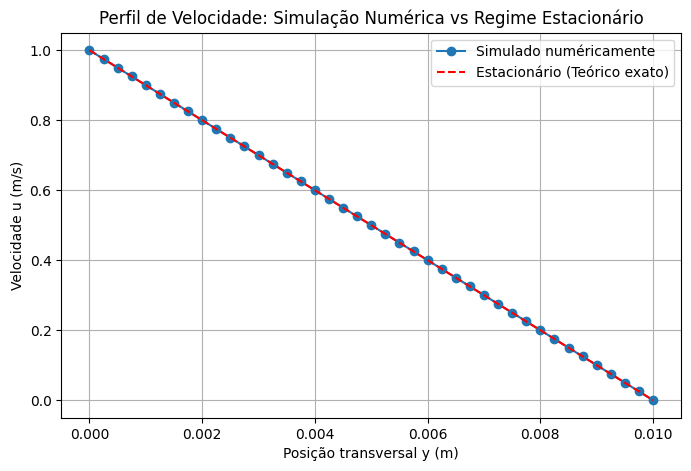

Diferença máxima em relação ao perfil estacionário: 1.6864359353441216e-09


In [5]:
# Extraindo os dados do teste estável feito no passo anterior
y = resultado_estavel_41["y"]
u_simulado = resultado_estavel_41["u"]

# Definindo as constantes do problema
H = 0.01
U = 1.0

# Calculando o perfil estacionário teórico: u_est(y) = U * (1 - y/H)
u_estacionario = U * (1 - y / H)

# Plotando os perfis para comparação
plt.figure(figsize=(8, 5))
plt.plot(y, u_simulado, 'o-', label="Simulado numéricamente")
plt.plot(y, u_estacionario, 'r--', label="Estacionário (Teórico exato)")
plt.xlabel("Posição transversal y (m)")
plt.ylabel("Velocidade u (m/s)")
plt.title("Perfil de Velocidade: Simulação Numérica vs Regime Estacionário")
plt.grid(True)
plt.legend()
plt.show()

# Calculando e imprimindo a diferença máxima (E_infinito)
erro_maximo = np.max(np.abs(u_simulado - u_estacionario))
print(f"Diferença máxima em relação ao perfil estacionário: {erro_maximo}")

# Atividade 6 - Verificação do perfil de velocidade

O gráfico ilustra a comparação entre a velocidade da simulação numérica e o perfil de velocidade estacionário (quando o sistema atinge o equilíbrio total).  

A diferença máxima calculada ($E_{\infty}$) representa o erro entre a nossa simulação no último instante de tempo calculado e a solução teórica final.  

Se essa diferença for considerável (maior do que um erro de arredondamento da máquina), isso indica que o tempo total simulado ainda não foi suficiente para que o movimento da placa superior se propagasse completamente por todo o fluido. Ou seja, o fluido ainda se encontra no regime transiente (fase de adaptação) e não atingiu plenamente o regime estacionário.  

# Atividade 7 - Conclusão

**Relação entre os conceitos:** O refinamento da malha espacial (diminuir o $\Delta y$) exige uma redução drástica no passo de tempo ($\Delta t$) para manter a simulação estável. Se o passo de tempo não for reduzido para respeitar o limite matemático ($r \le 1/2$), o método sofre de instabilidade numérica. Essa instabilidade faz com que os erros matemáticos sejam amplificados a cada iteração de forma irreal, até que o valor se torne tão grande que a memória do computador não consegue mais armazená-lo, causando a falha conhecida como overflow. Portanto, o overflow é apenas a consequência final e visível de uma instabilidade numérica que já estava corrompendo os dados físicos da simulação muito antes.  

**Correção da falha:** A alteração que de fato corrigiu a causa da falha na simulação foi a redução do passo de tempo ($\Delta t$) para um valor abaixo do limite máximo permitido ($0,0003125~s$ no caso da malha refinada), garantindo que $r \le 0,5$. Apenas alterar o tipo numérico para float64 não corrige a causa, apenas adia o momento em que o overflow acontece.